In [1]:
from google.colab import drive
drive.mount('/content/drive')
%cd /content/drive/MyDrive/Projects/karate-kumite-performance-profiles-lab/

Mounted at /content/drive
/content/drive/MyDrive/Projects/karate-kumite-performance-profiles-lab


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

OUTPUT_DIR = Path("outputs")

# Exploratory Data Analysis (EDA)

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

DATA_DIR = Path("data")
OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

FILES = {
    "Female-42kg": DATA_DIR / "female_42kg.csv",
    "Female-47kg": DATA_DIR / "female_47kg.csv",
    "Female-54kg": DATA_DIR / "female_54kg.csv",
}

P0_FEATURES = ["yuko", "waza_ari", "ippon", "attack", "defend",
               "longest_point_in_sec", "fastest_point_in_sec"]

TIMING_FEATURES    = ["longest_point_in_sec", "fastest_point_in_sec"]
NONTIMING_FEATURES = [c for c in P0_FEATURES if c not in TIMING_FEATURES]

S1_FEATURES = P0_FEATURES + ["match_attack", "match_defend"]
S2_FEATURES = P0_FEATURES + ["state_numeric", "hantei", "point_diff"]
STRUCTURAL_ZERO_FEATURES = ["yuko", "longest_point_in_sec", "fastest_point_in_sec"]


In [3]:
def load_weight_class(name, filepath):
    if filepath.exists():
        df = pd.read_csv(filepath, sep=";")
        df = df.dropna(how="all").reset_index(drop=True)
        df.columns = df.columns.str.strip()
    else:
        print(f"{filepath} not found")
        return None

    df["state_numeric"] = df["state"].str.lower().map({"win": 1, "lose": 0})
    return df

In [4]:
# @title Load Data
raw_data = {name: load_weight_class(name, path) for name, path in FILES.items()}

for name, df in raw_data.items():
  print("Data: ", name, " with ", df.shape[0], " samples and ", df.shape[1], " features")

print("")
print("Features: ")
for cfg_name, feats in [("P0", P0_FEATURES), ("S1", S1_FEATURES), ("S2", S2_FEATURES)]:
  print(cfg_name, ": ", feats)

print("")
print("Samples [P0 features only]: ")
display(raw_data["Female-42kg"][["name"] + P0_FEATURES].head(3))

Data:  Female-42kg  with  38  samples and  21  features
Data:  Female-47kg  with  38  samples and  21  features
Data:  Female-54kg  with  38  samples and  21  features

Features: 
P0 :  ['yuko', 'waza_ari', 'ippon', 'attack', 'defend', 'longest_point_in_sec', 'fastest_point_in_sec']
S1 :  ['yuko', 'waza_ari', 'ippon', 'attack', 'defend', 'longest_point_in_sec', 'fastest_point_in_sec', 'match_attack', 'match_defend']
S2 :  ['yuko', 'waza_ari', 'ippon', 'attack', 'defend', 'longest_point_in_sec', 'fastest_point_in_sec', 'state_numeric', 'hantei', 'point_diff']

Samples [P0 features only]: 


,name,yuko,waza_ari,ippon,attack,defend,longest_point_in_sec,fastest_point_in_sec
0,S. Mosleh,2,0,2,4,2,6,2
1,Vinogradova,0,0,0,4,1,0,0
2,Abellanosa,0,0,0,2,4,0,0


In [ ]:
# @title Data
wc = "Female-47kg" #@param ["Female-42kg", "Female-47kg", "Female-54kg"]
raw_data[wc][["name"] + P0_FEATURES]

,name,yuko,waza_ari,ippon,attack,defend,longest_point_in_sec,fastest_point_in_sec
0,Carolina Crinzz,4,0,1,5,7,4,2
1,B.Sirish,0,0,2,13,4,4,4
2,K.Kubacka,2,0,2,11,2,4,2
3,K.Chyhasova,0,0,0,4,3,0,0
4,S.Kostova,3,0,0,8,8,2,2
5,S.Rahman Jamhani,1,0,0,12,4,2,2
6,E.Cakravartty,0,0,2,5,8,4,4
7,K.Czepinska (1),3,0,0,12,5,2,2
8,M.Artelova,1,0,0,3,1,2,2
9,M.Lozo,0,0,0,4,1,0,0


In [ ]:
# @title Data Distribution Summary { run: "auto" }

wc = "Female-54kg" #@param ["Female-42kg", "Female-47kg", "Female-54kg"]
display(raw_data[wc][P0_FEATURES].describe())

,yuko,waza_ari,ippon,attack,defend,longest_point_in_sec,fastest_point_in_sec
count,38.000000,38.0,38.0,38.000000,38.000000,38.000000,38.000000
mean,1.947368,0.0,0.0,5.973684,3.447368,3.236842,1.842105
std,2.503483,0.0,0.0,1.668254,1.483192,2.487093,1.533875
min,0.000000,0.0,0.0,2.000000,0.000000,0.000000,0.000000
25%,0.000000,0.0,0.0,5.000000,3.000000,0.000000,0.000000
50%,1.000000,0.0,0.0,6.000000,3.000000,4.000000,2.000000
75%,3.000000,0.0,0.0,7.000000,4.750000,5.000000,3.000000
max,9.000000,0.0,0.0,11.000000,6.000000,6.000000,4.000000


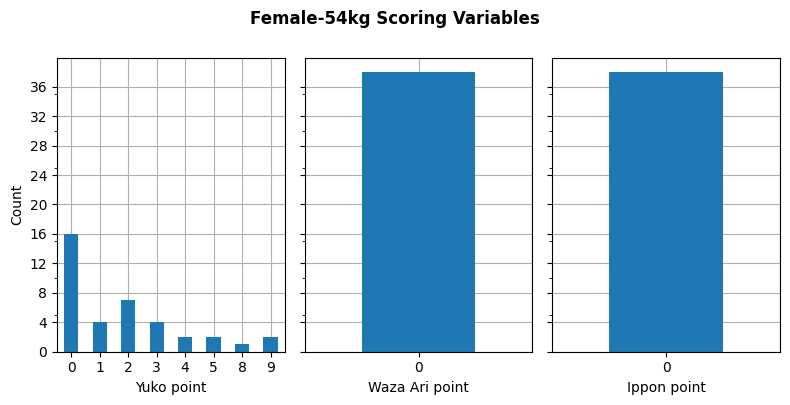

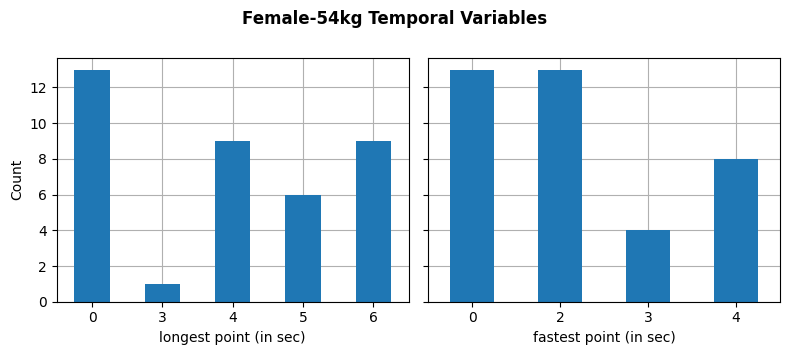

In [ ]:
# @title Scoring Variables Distribution { run: "auto" }
# @markdown Here the distribution of Scoring Variables for certain weight class (wc):

from matplotlib.ticker import MaxNLocator

wc = "Female-54kg" #@param ["Female-42kg", "Female-47kg", "Female-54kg"]
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(8, 4), sharey=True)
fig.suptitle(wc+" Scoring Variables", fontsize=12, fontweight='bold', y=1)

yuko_distribution = raw_data[wc][P0_FEATURES].yuko.value_counts().sort_index()
yuko_distribution.plot(kind="bar", rot=0, ax=axes[0])

axes[0].set_xlabel("Yuko point")
axes[0].set_ylabel("Count")

waza_ari_distribution = raw_data[wc][P0_FEATURES].waza_ari.value_counts().sort_index()
waza_ari_distribution.plot(kind="bar", rot=0, ax=axes[1])

axes[1].set_xlabel("Waza Ari point")
axes[1].set_ylabel("Count")

ippon_distribution = raw_data[wc][P0_FEATURES].ippon.value_counts().sort_index()
ippon_distribution.plot(kind="bar", rot=0, ax=axes[2])

axes[2].set_xlabel("Ippon point")
axes[2].set_ylabel("Count")

for ax in axes:
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))
    ax.grid(True)
    ax.set_axisbelow(True)

plt.tight_layout(rect=[0, 0, 1, 1])
plt.show()

fig2, axes2 = plt.subplots(nrows=1, ncols=2, figsize=(8, 3.5), sharey=True)
fig2.suptitle(wc+" Temporal Variables", fontsize=12, fontweight='bold', y=1)

long_distribution = (raw_data[wc][P0_FEATURES]
                     .longest_point_in_sec
                     .value_counts()
                     .sort_index())

long_distribution.plot(kind="bar", rot=0, ax=axes2[0])

axes2[0].set_xlabel("longest point (in sec)")
axes2[0].set_ylabel("Count")

fast_distribution = (raw_data[wc][P0_FEATURES]
                     .fastest_point_in_sec
                     .value_counts()
                     .sort_index())

fast_distribution.plot(kind="bar", rot=0, ax=axes2[1])

axes2[1].set_xlabel("fastest point (in sec)")
axes2[1].set_ylabel("Count")

for ax in axes2:
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))
    ax.grid(True)
    ax.set_axisbelow(True)

plt.tight_layout(rect=[0, 0, 1, 1])
plt.show()

# Comparative Clustering Performance on P<sub>0</sub>

In [ ]:
comparative_df     = pd.read_csv(OUTPUT_DIR / "table3_p0_clustering_results.csv")
comparative_column = ["Weight class", "Method", "Selected setting", "Sil.", "W/B", "Retained n (%)", "DBI", "Cluster sizes"]

comparative_df[comparative_column]

,Weight class,Method,Selected setting,Sil.,W/B,Retained n (%),DBI,Cluster sizes
0,Female-42kg,Ward,k=4,0.442,0.510,38 (100.0),0.872,"14, 5, 4, 15"
1,Female-42kg,k-Means,k=4,0.437,0.506,38 (100.0),0.931,"6, 15, 4, 13"
2,Female-42kg,RSKC-STOF,"k=4, s=2.21",0.442,0.510,38 (100.0),0.872,"15, 4, 5, 14"
3,Female-42kg,ARSK,"k=4, λ1=0.93, λ2=41.49",0.439,0.513,38 (100.0),0.899,"5, 13, 16, 4"
4,Female-42kg,DBSCAN,"ε=2.0, M=4",0.477,0.530,33 (86.8),0.807,"13, 5, 15"
5,Female-47kg,Ward,k=3,0.307,1.274,38 (100.0),1.277,"9, 7, 22"
6,Female-47kg,k-Means,k=5,0.356,0.501,38 (100.0),1.030,"10, 8, 7, 9, 4"
7,Female-47kg,RSKC-STOF,"k=5, s=2.21",0.319,0.670,38 (100.0),1.270,"9, 8, 9, 8, 4"
8,Female-47kg,ARSK,"k=5, λ1=1.32, λ2=40.61",0.319,0.670,38 (100.0),1.270,"8, 8, 9, 4, 9"
9,Female-47kg,DBSCAN,"ε=2.4, M=4",0.364,1.714,31 (81.6),0.882,"9, 22"


In [ ]:
comparative_TP_df     = pd.read_csv(OUTPUT_DIR / "table3_TP_clustering_results.csv")
comparative_TP_df

,weight_class,method,k,silhouette,dbi,retained_n,cluster_sizes
0,Female-42kg,Ward,4.0,0.339,1.138,38.0,"{0: 13, 1: 5, 2: 4, 3: 16}"
1,Female-42kg,k-Means,4.0,0.339,1.168,38.0,"{0: 4, 1: 13, 2: 6, 3: 15}"
2,Female-42kg,RSKC-STOF,4.0,0.334,1.143,38.0,"{0: 15, 1: 5, 2: 14, 3: 4}"
3,Female-42kg,ARSK,4.0,0.291,1.189,38.0,"{0: 4, 1: 6, 2: 18, 3: 10}"
4,Female-42kg,DBSCAN,2.0,0.339,0.974,31.0,"{0: 27, 1: 4}"
5,Female-47kg,Ward,3.0,0.303,1.343,38.0,"{0: 10, 1: 9, 2: 19}"
6,Female-47kg,k-Means,5.0,0.360,1.057,38.0,"{0: 10, 1: 4, 2: 9, 3: 8, 4: 7}"
7,Female-47kg,RSKC-STOF,2.0,0.336,1.455,38.0,"{0: 8, 1: 30}"
8,Female-47kg,ARSK,5.0,0.329,1.082,38.0,"{0: 12, 1: 7, 2: 4, 3: 9, 4: 6}"
9,Female-47kg,DBSCAN,NaN,NaN,NaN,NaN,NaN


In [ ]:
comparative_NT_df     = pd.read_csv(OUTPUT_DIR / "table3_NT_clustering_results.csv")
comparative_NT_df

,weight_class,method,k,silhouette,dbi,retained_n,cluster_sizes
0,Female-42kg,Ward,4.0,0.352,0.981,38.0,"{0: 5, 1: 11, 2: 4, 3: 18}"
1,Female-42kg,k-Means,4.0,0.364,0.923,38.0,"{0: 11, 1: 18, 2: 5, 3: 4}"
2,Female-42kg,RSKC-STOF,4.0,0.317,1.038,38.0,"{0: 10, 1: 4, 2: 5, 3: 19}"
3,Female-42kg,ARSK,4.0,0.313,1.168,38.0,"{0: 10, 1: 6, 2: 18, 3: 4}"
4,Female-42kg,DBSCAN,2.0,0.432,0.706,32.0,"{0: 28, 1: 4}"
5,Female-47kg,Ward,2.0,0.218,1.744,38.0,"{0: 19, 1: 19}"
6,Female-47kg,k-Means,5.0,0.333,0.944,38.0,"{0: 7, 1: 17, 2: 4, 3: 4, 4: 6}"
7,Female-47kg,RSKC-STOF,3.0,0.267,1.415,38.0,"{0: 7, 1: 25, 2: 6}"
8,Female-47kg,ARSK,5.0,0.298,1.021,38.0,"{0: 13, 1: 4, 2: 11, 3: 4, 4: 6}"
9,Female-47kg,DBSCAN,NaN,NaN,NaN,NaN,NaN


In [ ]:
comparative_SO_df     = pd.read_csv(OUTPUT_DIR / "table3_SO_clustering_results.csv")
comparative_SO_df

,weight_class,method,k,silhouette,dbi,retained_n,cluster_sizes
0,Female-42kg,Ward,2.0,0.243,1.286,24.0,"{0: 5, 1: 19}"
1,Female-42kg,k-Means,3.0,0.238,1.371,24.0,"{0: 6, 1: 14, 2: 4}"
2,Female-42kg,RSKC-STOF,2.0,0.222,1.622,24.0,"{0: 9, 1: 15}"
3,Female-42kg,ARSK,5.0,0.217,1.204,24.0,"{0: 5, 1: 4, 2: 4, 3: 4, 4: 7}"
4,Female-42kg,DBSCAN,2.0,0.248,1.235,20.0,"{0: 16, 1: 4}"
5,Female-47kg,Ward,2.0,0.327,1.342,29.0,"{0: 7, 1: 22}"
6,Female-47kg,k-Means,2.0,0.351,1.345,29.0,"{0: 8, 1: 21}"
7,Female-47kg,RSKC-STOF,2.0,0.351,1.345,29.0,"{0: 8, 1: 21}"
8,Female-47kg,ARSK,2.0,0.351,1.345,29.0,"{0: 8, 1: 21}"
9,Female-47kg,DBSCAN,NaN,NaN,NaN,NaN,NaN


# Cross Method Agreement

# Robustness (Stability)

In [8]:
stability = pd.read_csv(OUTPUT_DIR / 'table5_stability_fixed_vs_pipeline.csv')
stability.head()

,Weight class,Method,Model,Bootstrap admiss. (%),Bootstrap ARI median,ARI 5th pct.,LOAO admiss. (%),LOAO ARI median,Minimum ARI
0,Female-42kg,Ward,Fixed (as published),62.0,0.910,0.598,85.0,1.0,0.898
1,Female-42kg,Ward,Full pipeline,100.0,0.853,0.534,100.0,1.0,0.638
2,Female-42kg,k-Means,Fixed (as published),64.2,0.941,0.603,85.0,1.0,0.938
3,Female-42kg,k-Means,Full pipeline,100.0,0.869,0.572,100.0,1.0,0.695
4,Female-42kg,RSKC-STOF,Fixed (as published),58.0,0.758,0.430,85.0,1.0,0.357


In [9]:
# metric column in CSV  ->  (top header, sub header)
metric_map = {
    'Bootstrap admiss. (%)': ('Bootstrap', 'Admissible (%)'),
    'Bootstrap ARI median':  ('Bootstrap', 'ARI median'),
    'ARI 5th pct.':          ('Bootstrap', 'ARI 5th pct.'),
    'LOAO admiss. (%)':      ('LOAO', 'Admissible (%)'),
    'LOAO ARI median':       ('LOAO', 'ARI median'),
    'Minimum ARI':           ('LOAO', 'Minimum ARI'),
}
method_order = ['Ward', 'k-Means', 'RSKC-STOF', 'ARSK', 'DBSCAN']

s = stability.copy()
s['Model'] = s['Model'].replace({'Fixed (as published)': 'Fixed',
                                 'Full pipeline': 'Full'})
s['Method'] = pd.Categorical(s['Method'], categories=method_order, ordered=True)

# long -> wide: rows = (Weight class, Method), cols = (metric, Fixed/Full)
long = s.melt(id_vars=['Weight class', 'Method', 'Model'],
              value_vars=list(metric_map), var_name='metric')
wide = long.pivot_table(index=['Weight class', 'Method'],
                        columns=['metric', 'Model'],
                        values='value', observed=True)

# Δ = Fixed − Full (same sign convention as the manuscript: 62 − 100 = −38)
for m in metric_map:
  wide[(m, 'Δ')] = wide[(m, 'Full')] - wide[(m, 'Fixed')]

# order columns and build the 3-level header
cols = [(m, k) for m in metric_map for k in ['Fixed', 'Full', 'Δ']]
wide = wide[cols]
wide.columns = pd.MultiIndex.from_tuples(
    [(*metric_map[m], k) for m, k in cols],
    names=['Scheme', 'Metric', 'Model'])
wide = wide.sort_index()

# display formatting: % with 1 decimal, ARI with 3, Δ signed
fmt = {}
for c in wide.columns:
    dec = 1 if c[1] == 'Admissible (%)' else 3
    fmt[c] = f'{{:+.{dec}f}}' if c[2] == 'Δ' else f'{{:.{dec}f}}'

stability_df = wide.style.format(fmt, na_rep='–')
stability_df

In [ ]:
stab_long = pd.read_csv(OUTPUT_DIR / 'resampling_long.csv')
stab_long.head()

,analysis,weight_class,method,mode,rep,left_out,admissible,k,ARI_cond,ARI_cov,ARI_ret,s,lambda1,lambda2,eps,minpts
0,bootstrap,Female-42kg,Ward,fixed,0,NaN,False,4.0,1.000000,1.000000,1.000000,NaN,NaN,NaN,NaN,NaN
1,bootstrap,Female-42kg,Ward,reselected,0,NaN,True,2.0,0.536026,0.536026,0.536026,NaN,NaN,NaN,NaN,NaN
2,bootstrap,Female-42kg,k-Means,fixed,0,NaN,False,4.0,0.939384,0.939384,0.939384,NaN,NaN,NaN,NaN,NaN
3,bootstrap,Female-42kg,k-Means,reselected,0,NaN,True,2.0,0.598632,0.598632,0.598632,NaN,NaN,NaN,NaN,NaN
4,bootstrap,Female-42kg,RSKC-STOF,fixed,0,NaN,False,4.0,1.000000,1.000000,1.000000,NaN,NaN,NaN,NaN,NaN


/tmp/ipykernel_5233/867803814.py:23: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:k'` for the same effect.

  sns.stripplot(data=d, x="method", y="ARI_cond", hue="Model",
/tmp/ipykernel_5233/867803814.py:23: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:k'` for the same effect.

  sns.stripplot(data=d, x="method", y="ARI_cond", hue="Model",
/tmp/ipykernel_5233/867803814.py:23: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:k'` for the same effect.

  sns.stripplot(data=d, x="method", y="ARI_cond", hue="Model",


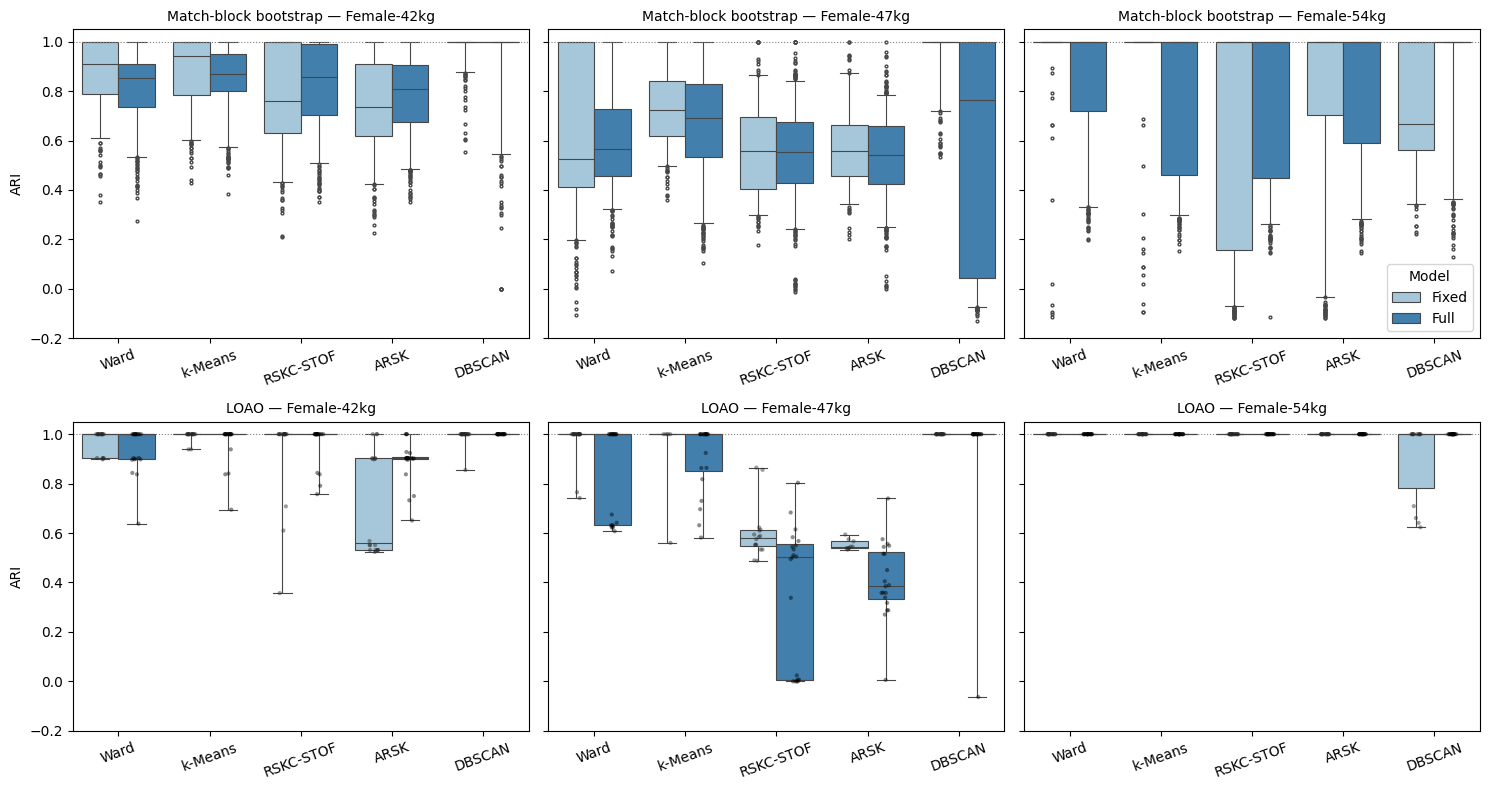

In [ ]:
# @title Figure: ARI distributions behind Table 5 (fixed vs full pipeline)
import seaborn as sns
import matplotlib.pyplot as plt

plot_df = stab_long[stab_long["admissible"]].copy()          # same rows Table 5 uses
plot_df["Model"] = plot_df["mode"].map({"fixed": "Fixed", "reselected": "Full"})

wcs = list(raw_data)
analyses = [("bootstrap", "Match-block bootstrap", (5, 95)),   # whisker = 5th / 95th pct
            ("loao",      "LOAO",                  (0, 100))]  # whisker = min / max
palette = {"Fixed": "#9ecae1", "Full": "#3182bd"}

fig, axes = plt.subplots(2, len(wcs), figsize=(5 * len(wcs), 8), sharey=True)
for r, (an, title, whis) in enumerate(analyses):
    for c, wc in enumerate(wcs):
        ax = axes[r, c]
        d = plot_df.query("analysis == @an and weight_class == @wc")
        sns.boxplot(data=d, x="method", y="ARI_cond", hue="Model",
                    order=method_order, hue_order=["Fixed", "Full"], palette=palette,
                    whis=whis, showfliers=(an == "bootstrap"), fliersize=2,
                    linewidth=0.8, ax=ax)
        if an == "loao":                                      # only 20 replicates: show them
            sns.stripplot(data=d, x="method", y="ARI_cond", hue="Model",
                          order=method_order, hue_order=["Fixed", "Full"], dodge=True,
                          size=3, color="k", alpha=0.45, legend=False, ax=ax)
        ax.axhline(1.0, ls=":", lw=0.8, c="grey")
        ax.set_ylim(-0.2, 1.05)
        ax.set_title(f"{title} — {wc}", fontsize=10)
        ax.set_xlabel("")
        ax.set_ylabel("ARI" if c == 0 else "")
        ax.tick_params(axis="x", rotation=20)
        if not (r == 0 and c == len(wcs) - 1) and ax.get_legend():
            ax.get_legend().remove()

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "fig5_stability_ari_boxplot.png", dpi=300, bbox_inches="tight")
plt.show()

/tmp/ipykernel_5233/775326387.py:25: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:k'` for the same effect.

  sns.stripplot(data=d, x="method", y="ARI_cond", hue="Model",


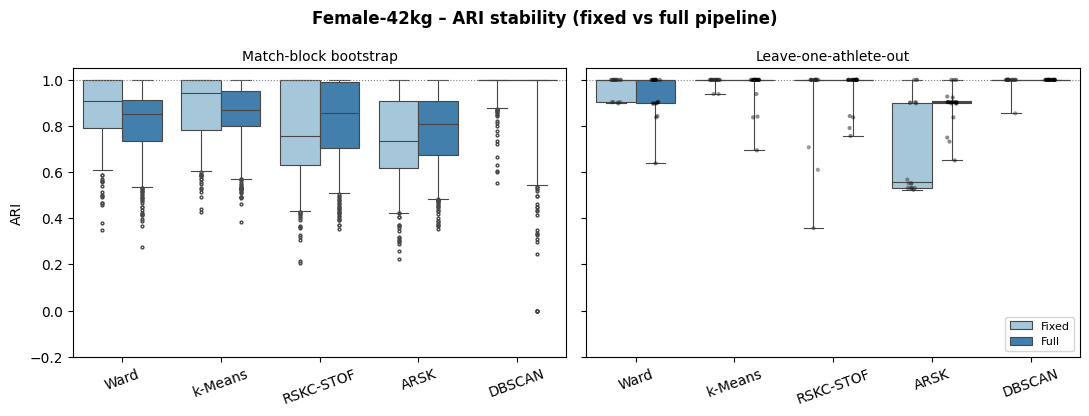

In [ ]:
# @title Figure 5: ARI stability per weight class { run: "auto" }
# @markdown Select the weight class (wc):
wc = "Female-42kg" #@param ["Female-42kg", "Female-47kg", "Female-54kg"]

import seaborn as sns
import matplotlib.pyplot as plt

plot_df = stab_long[stab_long["admissible"] & (stab_long["weight_class"] == wc)].copy()
plot_df["Model"] = plot_df["mode"].map({"fixed": "Fixed", "reselected": "Full"})

analyses = [("bootstrap", "Match-block bootstrap", (5, 95)),   # whisker = 5th / 95th pct
            ("loao",      "Leave-one-athlete-out", (0, 100))]  # whisker = min / max
palette = {"Fixed": "#9ecae1", "Full": "#3182bd"}

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
fig.suptitle(f"{wc} – ARI stability (fixed vs full pipeline)", fontsize=12, fontweight="bold")

for ax, (an, title, whis) in zip(axes, analyses):
    d = plot_df[plot_df["analysis"] == an]
    sns.boxplot(data=d, x="method", y="ARI_cond", hue="Model",
                order=method_order, hue_order=["Fixed", "Full"], palette=palette,
                whis=whis, showfliers=(an == "bootstrap"), fliersize=2,
                linewidth=0.8, ax=ax)
    if an == "loao":                                          # only 20 replicates: show them
        sns.stripplot(data=d, x="method", y="ARI_cond", hue="Model",
                      order=method_order, hue_order=["Fixed", "Full"], dodge=True,
                      size=3, color="k", alpha=0.45, legend=False, ax=ax)
    ax.axhline(1.0, ls=":", lw=0.8, c="grey")
    ax.set_ylim(-0.2, 1.05)
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("")
    ax.set_ylabel("ARI" if ax is axes[0] else "")
    ax.tick_params(axis="x", rotation=20)

axes[0].get_legend().remove()
axes[1].legend(title="", loc="lower right", fontsize=8)

plt.tight_layout()
#plt.savefig(OUTPUT_DIR / f"fig5_stability_ari_{wc}.png", dpi=300, bbox_inches="tight")
plt.show()

In [5]:
consensus = pd.read_csv(OUTPUT_DIR / 'table8_consensus_fixed_vs_pipeline.csv')
consensus.head()


,Weight class,Method,Model,Admiss. (%),Within,Between,Gap,PAC
0,Female-42kg,Ward,Fixed (as published),32.4,0.953,0.013,0.940,0.047
1,Female-42kg,Ward,Full pipeline,100.0,0.962,0.154,0.808,0.273
2,Female-42kg,k-Means,Fixed (as published),42.0,0.971,0.008,0.963,0.033
3,Female-42kg,k-Means,Full pipeline,100.0,0.995,0.079,0.917,0.172
4,Female-42kg,RSKC-STOF,Fixed (as published),37.0,0.827,0.039,0.787,0.287


In [10]:
# @title Table 8: consensus stability, Fixed vs Full pipeline (one table per weight class)
# Uses `table8` from the "Table 8: consensus stability over 80% subsamples" cell.

FIXED_LABEL, FULL_LABEL = "Fixed (as published)", "Full pipeline"
METHOD_ORDER = ["Ward", "k-Means", "RSKC-STOF", "ARSK", "DBSCAN"]
ADM_COL = next(c for c in consensus.columns if c.startswith("Admiss"))   # "Admissible (%)"
METRICS = [ADM_COL, "Within", "Between", "Gap", "PAC"]               # reorder here if needed

def delta(fixed, full):
    """Δ = Full − Fixed (absolute difference)."""
    return np.nan if pd.isna(fixed) or pd.isna(full) else full - fixed

def consensus_block(wc, metrics):
    """Wide table: rows = methods, columns = (metric, Fixed | Full | Δ)."""
    sub = consensus[consensus["Weight class"] == wc]
    fx = sub[sub["Model"] == FIXED_LABEL].set_index("Method")
    fu = sub[sub["Model"] == FULL_LABEL].set_index("Method")
    methods = [m for m in METHOD_ORDER if m in fx.index or m in fu.index]
    cols = {}
    for metric in metrics:
        f = fx[metric].reindex(methods)
        u = fu[metric].reindex(methods)
        cols[(metric, "Fixed")] = f
        cols[(metric, "Full")] = u
        cols[(metric, "Δ")] = pd.Series([delta(a, b) for a, b in zip(f, u)], index=methods)
    out = pd.DataFrame(cols)
    out.columns = pd.MultiIndex.from_tuples(out.columns, names=[None, "Method"])
    out.index.name = None      # "Method" sits in the header corner -> no empty header row
    return out

def show_block(df, title):
    fmt = {}
    for metric, sub in df.columns:
        dec = 1 if metric == ADM_COL else 3
        fmt[(metric, sub)] = ("{:+.%df}" if sub == "Δ" else "{:.%df}") % dec
    sty = (df.style.format(fmt, na_rep="—")
             .set_caption(title)
             .set_table_styles([
                 {"selector": "caption", "props": "font-weight:bold; font-size:13px; text-align:center;"},
                 {"selector": "th", "props": "text-align:center; background:#dce6f1; border:1px solid #888;"},
                 {"selector": "td", "props": "text-align:center; border:1px solid #888; padding:2px 10px;"}]))
    display(sty)

table8_by_class = {}
for wc in raw_data:
    wc_label = wc.replace("-", "")                     # "Female42kg"
    table8_by_class[wc] = consensus_block(wc, METRICS)
    show_block(table8_by_class[wc], f"Table 8. Consensus Stability of P₀ Partitions – {wc_label}")
    #table8_by_class[wc].round(3).to_csv(OUTPUT_DIR / f"table8_consensus_{wc_label}.csv")

# All weight classes in one Excel file, one sheet per class
#with pd.ExcelWriter(OUTPUT_DIR / "table8_consensus_fixed_vs_full.xlsx") as xw:
#    for wc in raw_data:
#        table8_by_class[wc].round(3).to_excel(xw, sheet_name=wc.replace("-", ""))

#print("Δ = Full − Fixed. Within/Between/Gap/PAC are computed over admissible subsamples only.")

In [12]:
# @title Table 5: stability, Fixed vs Full pipeline (manuscript style, per weight class)
# Uses `table5` from the "Table 5: stability under match-block bootstrap and LOAO" cell.

FIXED_LABEL, FULL_LABEL = "Fixed (as published)", "Full pipeline"
METHOD_ORDER = ["Ward", "k-Means", "RSKC-STOF", "ARSK", "DBSCAN"]

# column in table5  ->  short header in the manuscript table
T5_BOOT = {"Bootstrap admiss. (%)": "Admiss. (%)",
           "Bootstrap ARI median":  "ARI median",
           "ARI 5th pct.":          "ARI 5th pct."}
T5_LOAO = {"LOAO admiss. (%)":      "Admiss. (%)",
           "LOAO ARI median":       "ARI median",
           "Minimum ARI":           "Minimum ARI"}

SPLIT = True   # True -> Table 5.a (bootstrap) + 5.b (LOAO); False -> one wide table

def delta(fixed, full):
    """Δ = Full − Fixed (positive = full pipeline higher)."""
    return np.nan if pd.isna(fixed) or pd.isna(full) else full - fixed

def fixed_full_block(src, wc, metric_map):
    """Rows = methods, columns = (short metric name, Fixed | Full | Δ)."""
    sub = src[src["Weight class"] == wc]
    fx = sub[sub["Model"] == FIXED_LABEL].set_index("Method")
    fu = sub[sub["Model"] == FULL_LABEL].set_index("Method")
    methods = [m for m in METHOD_ORDER if m in fx.index or m in fu.index]
    cols = {}
    for col, short in metric_map.items():
        f = fx[col].reindex(methods)
        u = fu[col].reindex(methods)
        cols[(short, "Fixed")] = f
        cols[(short, "Full")] = u
        cols[(short, "Δ")] = pd.Series([delta(a, b) for a, b in zip(f, u)], index=methods)
    out = pd.DataFrame(cols)
    out.columns = pd.MultiIndex.from_tuples(out.columns, names=[None, "Method"])
    out.index.name = None
    return out

def show_block(df, title):
    fmt = {}
    for metric, sub in df.columns:
        dec = 1 if "(%)" in metric else 3
        fmt[(metric, sub)] = ("{:+.%df}" if sub == "Δ" else "{:.%df}") % dec
    sty = (df.style.format(fmt, na_rep="—")
             .set_caption(title)
             .set_table_styles([
                 {"selector": "caption", "props": "font-weight:bold; font-size:13px; text-align:center;"},
                 {"selector": "th", "props": "text-align:center; background:#dce6f1; border:1px solid #888;"},
                 {"selector": "td", "props": "text-align:center; border:1px solid #888; padding:2px 10px;"}]))
    display(sty)
    return sty

stability_by_class = {}
for wc in raw_data:
    wc_label = wc.replace("-", "")                       # "Female42kg"
    if SPLIT:
        boot = fixed_full_block(stability, wc, T5_BOOT)
        loao = fixed_full_block(stability, wc, T5_LOAO)
        stability_by_class[wc] = {"bootstrap": boot, "loao": loao}
        show_block(boot, f"Table 5.a. Stability under Match Perturbation – "
                         f"Match-Block Bootstrap (500 replicates), {wc_label}")
        print("")
        show_block(loao, f"Table 5.b. Stability under Athlete Perturbation – "
                         f"Leave-One-Athlete-Out (20 replicates), {wc_label}")
        print("")

    else:
        # one wide table: prefix the headers so the two "Admiss. (%)" columns stay distinct
        wide_map = {**{k: f"Bootstrap {v}" for k, v in T5_BOOT.items()},
                    **{k: f"LOAO {v}"      for k, v in T5_LOAO.items()}}
        wide = fixed_full_block(stability, wc, wide_map)
        stability_by_class[wc] = wide
        show_block(wide, f"Table 5. Stability of P₀ Partitions – {wc_label}")